## Task 1 - Implementation and Algorithm Trace

`A = [4, 2, 2, 8, 3, 3, 1]`

Counting Sort accepts nonnegative integers. It uses an input array `A`, a counting array `C` of size `k = max(A) + 1`, and an output array `B`. The reusable stable counting pass below also supports sorting records by an integer key; Task 2 uses it for decimal digits.


In [1]:
def stable_counting_pass(A, k, key, trace=False):
    C = [0] * k
    for value in A:
        C[key(value)] += 1
    if trace:
        print('Frequency array (index = value):')
        print(C)

    # C[v] becomes the number of input elements with key <= v.
    for value in range(1, k):
        C[value] += C[value - 1]
    if trace:
        print('Cumulative counts:')
        print(C)

    B = [None] * len(A)
    # Traverse backwards so equal keys keep their original order.
    for j in range(len(A) - 1, -1, -1):
        digit = key(A[j])
        position = C[digit] - 1
        B[position] = A[j]
        C[digit] -= 1
        if trace:
            print(f'A[{j}] = {A[j]} -> B[{position}]: {B}')
    return B


def counting_sort(A, trace=False):
    if any(not isinstance(value, int) or value < 0 for value in A):
        raise ValueError('Counting Sort requires nonnegative integers.')
    if not A:
        return []
    maximum = max(A)
    if trace:
        print('Maximum input value:', maximum)
        print('Counting array size:', maximum + 1)
    return stable_counting_pass(A, maximum + 1, lambda value: value, trace)


A = [4, 2, 2, 8, 3, 3, 1]
print('Original array:')
print(A)
result = counting_sort(A, trace=True)
print('Final sorted array:')
print(result)
assert result == [1, 2, 2, 3, 3, 4, 8]


Original array:
[4, 2, 2, 8, 3, 3, 1]
Maximum input value: 8
Counting array size: 9
Frequency array (index = value):
[0, 1, 2, 2, 1, 0, 0, 0, 1]
Cumulative counts:
[0, 1, 3, 5, 6, 6, 6, 6, 7]
A[6] = 1 -> B[0]: [1, None, None, None, None, None, None]
A[5] = 3 -> B[4]: [1, None, None, None, 3, None, None]
A[4] = 3 -> B[3]: [1, None, None, 3, 3, None, None]
A[3] = 8 -> B[6]: [1, None, None, 3, 3, None, 8]
A[2] = 2 -> B[2]: [1, None, 2, 3, 3, None, 8]
A[1] = 2 -> B[1]: [1, 2, 2, 3, 3, None, 8]
A[0] = 4 -> B[5]: [1, 2, 2, 3, 3, 4, 8]
Final sorted array:
[1, 2, 2, 3, 3, 4, 8]


### Answers

1. **Why are comparisons between input elements unnecessary?** Each integer is used directly as a counting-array index. Its frequency determines its output positions; no pairwise ordering comparisons are needed.
2. **What is the purpose of the counting array?** Initially, `C[v]` records how often value `v` occurs. For this input, the frequency array is `[0, 1, 2, 2, 1, 0, 0, 0, 1]`.
3. **Why are cumulative counts used?** They give the number of elements at most each value and therefore the end of that value's output segment. Here they are `[0, 1, 3, 5, 6, 6, 6, 6, 7]`. The next available position for value `v` is `C[v] - 1`; decrementing the count moves to its previous available position.
4. **How is stability preserved?** The input is traversed from right to left. A later equal element receives a later output position. The two `2`s from original indices 1 and 2 occupy output indices 1 and 2 in the same order; the two `3`s from indices 4 and 5 occupy indices 3 and 4 in the same order.
5. **What if the maximum value is very large?** The counting array has `max(A) + 1` entries, including absent values. A sparse, very large range therefore requires excessive memory and initialization time even for a short input.

Running time is `Θ(n + k)` in all cases for this implementation, where `n` is the input length and `k` is the value-range size. Auxiliary space is `Θ(n + k)` for the counting and output arrays.


## Task 2 - Radix Sort and Algorithm Trace

`A = [170, 45, 75, 90, 802, 24, 2, 66]`

LSD Radix Sort processes decimal digits from the least significant to the most significant. Each pass uses the **same stable Counting Sort procedure** from Task 1 with digit key `(value // exponent) % 10` and ten counting entries. The input must contain nonnegative integers.


In [2]:
def radix_sort(A, trace=False):
    if any(not isinstance(value, int) or value < 0 for value in A):
        raise ValueError('Radix Sort requires nonnegative integers.')
    if not A:
        return []
    maximum = max(A)
    digits = 1
    remaining = maximum
    while remaining >= 10:
        remaining //= 10
        digits += 1
    if trace:
        print('Maximum input value:', maximum)
        print('Maximum number of digits:', digits)

    result = A.copy()
    exponent = 1
    names = ['units', 'tens', 'hundreds']
    for position in range(digits):
        result = stable_counting_pass(
            result, 10, lambda value: (value // exponent) % 10
        )
        if trace:
            name = names[position] if position < 3 else f'10^{position}'
            print(f'After sorting by {name} digit:')
            print(result)
        exponent *= 10
    return result


A = [170, 45, 75, 90, 802, 24, 2, 66]
print('Original array:')
print(A)
result = radix_sort(A, trace=True)
print('Final sorted array:')
print(result)
assert result == [2, 24, 45, 66, 75, 90, 170, 802]


Original array:
[170, 45, 75, 90, 802, 24, 2, 66]
Maximum input value: 802
Maximum number of digits: 3
After sorting by units digit:
[170, 90, 802, 2, 24, 45, 75, 66]
After sorting by tens digit:
[802, 2, 24, 45, 66, 170, 75, 90]
After sorting by hundreds digit:
[2, 24, 45, 66, 75, 90, 170, 802]
Final sorted array:
[2, 24, 45, 66, 75, 90, 170, 802]


### Answers

1. **Why must each digit sort be stable?** Equal current digits must preserve the ordering already established by lower digits. Otherwise a more significant digit pass could destroy the earlier work and produce an incorrect final order.
2. **How many passes are needed here?** Three: units, tens, and hundreds, since the maximum value is `802`.
3. **How are shorter numbers handled?** Missing leading digits act as zeros. For example, `2` is treated as `002`, and `45` as `045`; integer division gives these zero digits automatically.
4. **How do digits influence the running time?** Every additional position requires another full stable sorting pass. For fixed `n` and base `b`, the work grows linearly with `d`.
5. **How are Radix Sort and Counting Sort related?** Radix Sort is a sequence of stable Counting Sort passes, each sorting one digit rather than the entire integer. Each pass needs `b` counting entries, so a large maximum integer does not require a counting array covering its entire value range.

The units pass gives `[170, 90, 802, 2, 24, 45, 75, 66]`; the tens pass gives `[802, 2, 24, 45, 66, 170, 75, 90]`; the hundreds pass gives the final sorted array.

Running time is `Θ(d(n + b))`, where `d` is the number of digit positions and `b` is the number of possible digit values (`b = 10` here). Auxiliary space is `Θ(n + b)` because arrays are reused or replaced between passes rather than stored for every digit.


## Task 3 - Bucket Sort and Algorithm Trace

`A = [0.78, 0.17, 0.39, 0.26, 0.72, 0.94, 0.21, 0.12, 0.23, 0.68]`

All values must belong to `[0, 1)`. Create exactly `n = len(A)` buckets and assign each value `x` to bucket `floor(n*x)`. Insertion Sort within each bucket follows the implementation used in the previous labs.


In [3]:
import math


def insertion_sort(A):
    for j in range(1, len(A)):
        key = A[j]
        i = j - 1
        while i >= 0 and A[i] > key:
            A[i + 1] = A[i]
            i -= 1
        A[i + 1] = key
    return A


def bucket_sort(A, trace=False):
    n = len(A)
    buckets = [[] for _ in range(n)]
    for value in A:
        if not 0 <= value < 1:
            raise ValueError('Bucket Sort requires real values in [0, 1).')
        index = math.floor(n * value)
        buckets[index].append(value)
    if trace:
        print('Number of buckets:', n)
        print('Buckets before sorting:')
        for index, bucket in enumerate(buckets):
            print(f'Bucket {index}: {bucket}')

    for bucket in buckets:
        insertion_sort(bucket)
    if trace:
        print('After sorting individual buckets:')
        for index, bucket in enumerate(buckets):
            print(f'Bucket {index}: {bucket}')

    result = []
    for bucket in buckets:
        result.extend(bucket)
    return result


A = [0.78, 0.17, 0.39, 0.26, 0.72, 0.94, 0.21, 0.12, 0.23, 0.68]
print('Original array:')
print(A)
result = bucket_sort(A, trace=True)
print('Final sorted array:')
print(result)
assert result == [0.12, 0.17, 0.21, 0.23, 0.26, 0.39, 0.68, 0.72, 0.78, 0.94]


Original array:
[0.78, 0.17, 0.39, 0.26, 0.72, 0.94, 0.21, 0.12, 0.23, 0.68]
Number of buckets: 10
Buckets before sorting:
Bucket 0: []
Bucket 1: [0.17, 0.12]
Bucket 2: [0.26, 0.21, 0.23]
Bucket 3: [0.39]
Bucket 4: []
Bucket 5: []
Bucket 6: [0.68]
Bucket 7: [0.78, 0.72]
Bucket 8: []
Bucket 9: [0.94]
After sorting individual buckets:
Bucket 0: []
Bucket 1: [0.12, 0.17]
Bucket 2: [0.21, 0.23, 0.26]
Bucket 3: [0.39]
Bucket 4: []
Bucket 5: []
Bucket 6: [0.68]
Bucket 7: [0.72, 0.78]
Bucket 8: []
Bucket 9: [0.94]
Final sorted array:
[0.12, 0.17, 0.21, 0.23, 0.26, 0.39, 0.68, 0.72, 0.78, 0.94]


### Answers

1. **Why use buckets?** They divide `[0, 1)` into ordered intervals of width `1/n`. Every value in a lower-index bucket precedes every value in a higher-index bucket, so concatenating individually sorted buckets gives a sorted array.
2. **Why use Insertion Sort inside them?** It is simple, has low overhead for small lists, and takes `Θ(m)` best-case and `Θ(m²)` worst-case time for a bucket of size `m`.
3. **What happens with approximately uniform inputs?** Values tend to spread across the buckets. With independent uniform draws and `n` buckets, the expected occupancy is one per bucket and the expected total sorting work is linear.
4. **What if most elements enter the same bucket?** That bucket becomes large. Insertion Sort can require quadratic work, particularly for reverse-ordered values, so the overall worst case is `Θ(n²)`. A large bucket that is already sorted need not take quadratic time.
5. **When is expected linear time possible?** Assume independent, uniformly distributed values in `[0, 1)`, `n` equal-width buckets, constant-time bucket assignment, and constant-time arithmetic/comparisons. These conditions bound the expected sum of squared bucket occupancies by `Θ(n)`.

Expected running time is `Θ(n)` under those assumptions; worst-case time is `Θ(n²)` with Insertion Sort. Auxiliary space is `Θ(n)` for the bucket lists, their elements, and the concatenated output.


## Task 4 - Experimental Analysis and Comparison

### Part A - Experimental Measurements

All times below are wall-clock seconds measured with `time.perf_counter()`. Each mean uses **five runs with newly generated arrays**. Generation and the caller's copy happen before the timer; correctness checks happen after it. Sorting includes the algorithms' own validation, allocations, and internal copies. Fixed random seeds reproduce the inputs. Exact times depend on the computer and Python environment.

The required sizes are `100, 500, 1000, 5000, 10000, 50000`. Counting Sort receives integers in `[0, 999]`, Radix Sort receives integers in `[0, 999999]`, and Bucket Sort receives uniformly distributed real values in `[0, 1)`. These are different input types and ranges, so the results compare behavior under these specified conditions, rather than a fully controlled comparison on identical inputs.


      n    Counting (s)       Radix (s)      Bucket (s)
-------------------------------------------------------
    100        0.000093        0.000170        0.000046
    500        0.000220        0.000836        0.000216
   1000        0.000355        0.001679        0.000469
   5000        0.001543        0.008288        0.002169
  10000        0.002730        0.016788        0.010498
  50000        0.013453        0.086930        0.037911


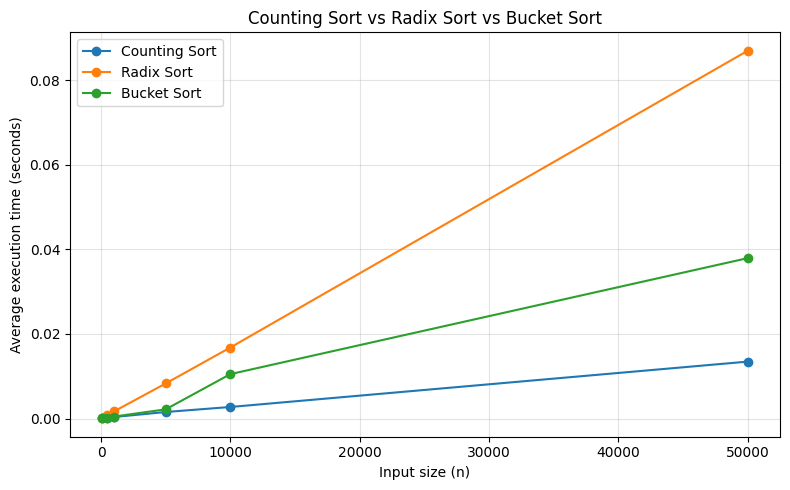

In [4]:
import random
import time
import matplotlib.pyplot as plt


def measure_sort(sort_function, values):
    data = values.copy()
    start = time.perf_counter()
    result = sort_function(data)
    elapsed = time.perf_counter() - start
    assert result == sorted(values)
    return elapsed


sizes = [100, 500, 1000, 5000, 10000, 50000]
repeats = 5
algorithms = {
    'Counting Sort': counting_sort,
    'Radix Sort': radix_sort,
    'Bucket Sort': bucket_sort,
}
input_generators = {
    'Counting Sort': lambda rng, n: [rng.randrange(1000) for _ in range(n)],
    'Radix Sort': lambda rng, n: [rng.randrange(1000000) for _ in range(n)],
    'Bucket Sort': lambda rng, n: [rng.random() for _ in range(n)],
}
comparison_times = {name: [] for name in algorithms}
comparison_runs = {name: [] for name in algorithms}
for n in sizes:
    for algorithm_index, (name, sort_function) in enumerate(algorithms.items()):
        runs = []
        for trial in range(repeats):
            rng = random.Random(20261013 + 100 * n + 10 * algorithm_index + trial)
            values = input_generators[name](rng, n)
            runs.append(measure_sort(sort_function, values))
        comparison_runs[name].append(runs)
        comparison_times[name].append(sum(runs) / repeats)

print(f"{'n':>7} {'Counting (s)':>15} {'Radix (s)':>15} {'Bucket (s)':>15}")
print('-' * 55)
for row in zip(sizes, *comparison_times.values()):
    print(f'{row[0]:>7} {row[1]:>15.6f} {row[2]:>15.6f} {row[3]:>15.6f}')

plt.figure(figsize=(8, 5))
for name, times in comparison_times.items():
    plt.plot(sizes, times, marker='o', label=name)
plt.xlabel('Input size (n)')
plt.ylabel('Average execution time (seconds)')
plt.title('Counting Sort vs Radix Sort vs Bucket Sort')
plt.legend()
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()


### Part B - Counting Sort: Value Range

Use `n = 10000` and the ranges `[0, 99]`, `[0, 999]`, and `[0, 99999]`. Each range is measured on five independently generated arrays. The implementation allocates `max(A) + 1` entries, which may be slightly less than the full generating range size `k`.


      n        Value range         k    Average time (s)
-----------------------------------------------------------
  10000            [0, 99]       100            0.002724
  10000           [0, 999]      1000            0.002765
  10000         [0, 99999]    100000            0.010975


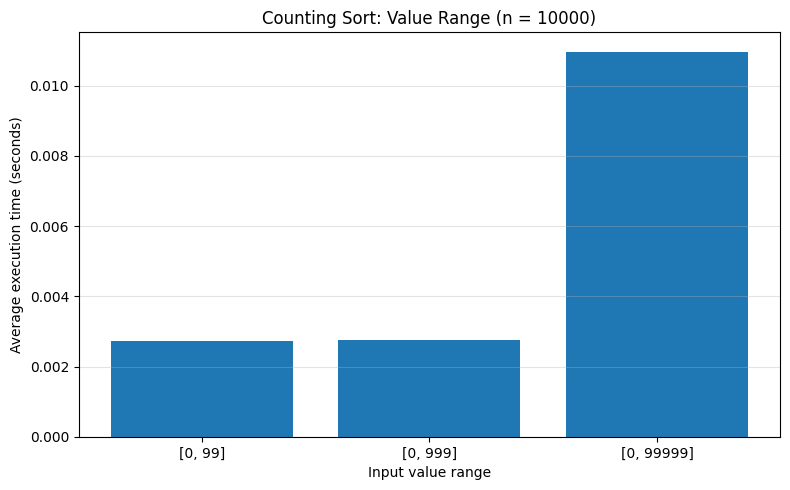

In [5]:
characteristic_n = 10000
counting_ranges = [100, 1000, 100000]
counting_range_times = []
counting_range_runs = []
for k in counting_ranges:
    runs = []
    for trial in range(repeats):
        rng = random.Random(20261013 + k + trial)
        values = [rng.randrange(k) for _ in range(characteristic_n)]
        runs.append(measure_sort(counting_sort, values))
    counting_range_runs.append(runs)
    counting_range_times.append(sum(runs) / repeats)

print(f"{'n':>7} {'Value range':>18} {'k':>9} {'Average time (s)':>19}")
print('-' * 59)
for k, elapsed in zip(counting_ranges, counting_range_times):
    label = f'[0, {k - 1}]'
    print(f'{characteristic_n:>7} {label:>18} {k:>9} {elapsed:>19.6f}')

plt.figure(figsize=(8, 5))
plt.bar([f'[0, {k - 1}]' for k in counting_ranges], counting_range_times)
plt.xlabel('Input value range')
plt.ylabel('Average execution time (seconds)')
plt.title('Counting Sort: Value Range (n = 10000)')
plt.grid(True, axis='y', alpha=0.35)
plt.tight_layout()
plt.show()


### Part B - Radix Sort: Number of Digits

Use `n = 10000` with values from `[0, 99]`, `[0, 9999]`, and `[0, 999999]`. These cases require two, four, and six decimal passes respectively. Every generated sample is checked to have the intended maximum digit count. Each mean uses five independently generated arrays.


      n        Value range  Passes d    Average time (s)
-----------------------------------------------------------
  10000            [0, 99]         2            0.005960
  10000          [0, 9999]         4            0.011389
  10000        [0, 999999]         6            0.016649


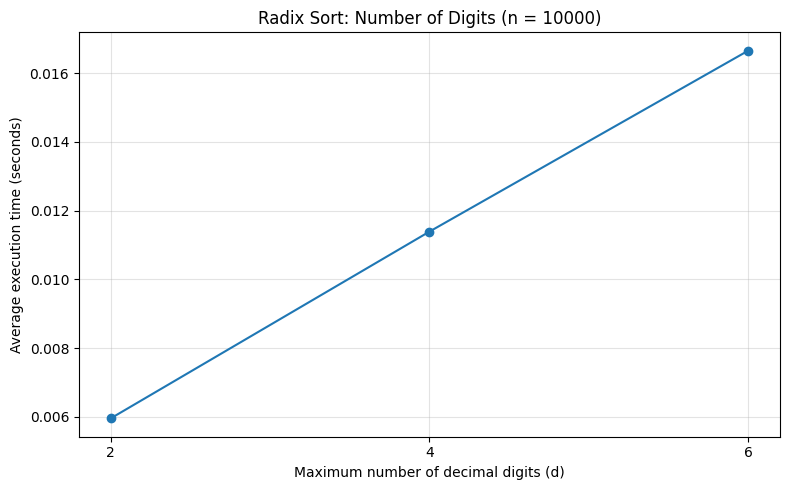

In [6]:
radix_digits = [2, 4, 6]
radix_digit_times = []
radix_digit_runs = []
for digits in radix_digits:
    runs = []
    limit = 10 ** digits
    for trial in range(repeats):
        rng = random.Random(20261013 + 100 * digits + trial)
        values = [rng.randrange(limit) for _ in range(characteristic_n)]
        assert len(str(max(values))) == digits
        runs.append(measure_sort(radix_sort, values))
    radix_digit_runs.append(runs)
    radix_digit_times.append(sum(runs) / repeats)

print(f"{'n':>7} {'Value range':>18} {'Passes d':>9} {'Average time (s)':>19}")
print('-' * 59)
for digits, elapsed in zip(radix_digits, radix_digit_times):
    label = f'[0, {10 ** digits - 1}]'
    print(f'{characteristic_n:>7} {label:>18} {digits:>9} {elapsed:>19.6f}')

plt.figure(figsize=(8, 5))
plt.plot(radix_digits, radix_digit_times, marker='o', label='Radix Sort')
plt.xticks(radix_digits)
plt.xlabel('Maximum number of decimal digits (d)')
plt.ylabel('Average execution time (seconds)')
plt.title('Radix Sort: Number of Digits (n = 10000)')
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()


### Part B - Bucket Sort: Distribution

Use `n = 10000` buckets for both uniformly distributed values in `[0, 1)` and values concentrated uniformly in `[0, 0.1)`. Five independently generated arrays are measured for each case. The same seed within a trial allows concentration to be the only input-generation change. The additional occupancy statistics explain the timing difference; they are calculated outside the timed region.


Distribution                    n    Average time (s)   Occupied buckets   Largest bucket
-----------------------------------------------------------------------------------------
Uniform [0, 1)              10000            0.004648             6324.8              7.2
Concentrated [0, 0.1)       10000            0.010937             1000.0             21.4


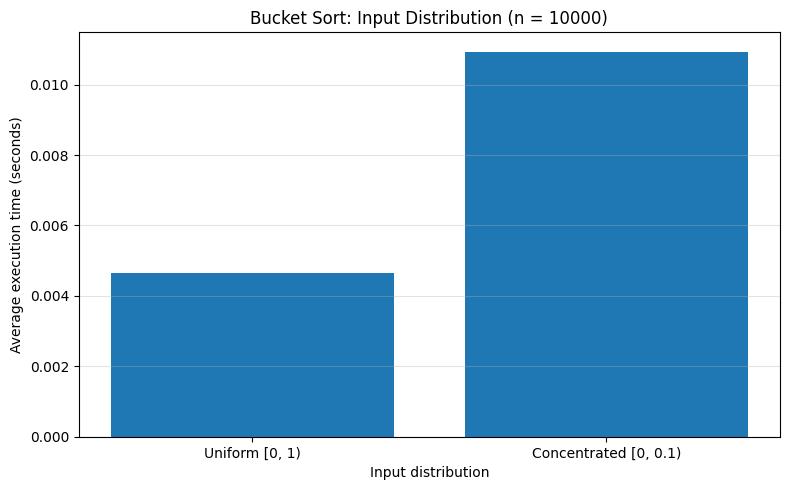

In [7]:
distributions = {'Uniform [0, 1)': 1.0, 'Concentrated [0, 0.1)': 0.1}
bucket_distribution_times = []
bucket_distribution_runs = []
bucket_occupancy = []
for label, width in distributions.items():
    runs = []
    occupied_runs = []
    largest_runs = []
    for trial in range(repeats):
        rng = random.Random(20261013 + 1000 + trial)
        values = [width * rng.random() for _ in range(characteristic_n)]
        runs.append(measure_sort(bucket_sort, values))
        occupancies = [0] * characteristic_n
        for value in values:
            occupancies[math.floor(characteristic_n * value)] += 1
        occupied_runs.append(sum(count > 0 for count in occupancies))
        largest_runs.append(max(occupancies))
    bucket_distribution_runs.append(runs)
    bucket_distribution_times.append(sum(runs) / repeats)
    bucket_occupancy.append((sum(occupied_runs) / repeats, sum(largest_runs) / repeats))

print(f"{'Distribution':<25} {'n':>7} {'Average time (s)':>19} {'Occupied buckets':>18} {'Largest bucket':>16}")
print('-' * 89)
for label, elapsed, (occupied, largest) in zip(
    distributions, bucket_distribution_times, bucket_occupancy
):
    print(f'{label:<25} {characteristic_n:>7} {elapsed:>19.6f} {occupied:>18.1f} {largest:>16.1f}')

plt.figure(figsize=(8, 5))
plt.bar(list(distributions), bucket_distribution_times)
plt.xlabel('Input distribution')
plt.ylabel('Average execution time (seconds)')
plt.title('Bucket Sort: Input Distribution (n = 10000)')
plt.grid(True, axis='y', alpha=0.35)
plt.tight_layout()
plt.show()


### Answers - Part C: Discussion

1. **How does time change as `n` increases?** With fixed generating ranges, decimal base, and uniform Bucket Sort inputs, all three algorithms have approximately linear large-input growth. Counting Sort performs `Θ(n + k)` work, Radix Sort performs `Θ(d(n + b))` work with at most six passes here, and Bucket Sort has expected `Θ(n)` work. Fixed allocation costs and timing noise can affect the smaller sizes. At `n = 50000`, the averages are approximately 0.013453 s for Counting Sort, 0.086930 s for Radix Sort, and 0.037911 s for Bucket Sort. Counting Sort is fastest at this size under the specified conditions. Bucket Sort's 10000-element mean in Part A is higher than its corresponding Part B mean; separate trials, allocation/garbage-collection costs, and timing variability can affect the exact values, so isolated timing ratios are not exact complexity estimates.
2. **How does the value range affect Counting Sort?** A wider range increases the number of counting entries and cumulative-count iterations, as well as memory use. In Part B, `n` stays fixed while the range grows from 100 to 100000 possible values. The measured means are 0.002724 s, 0.002765 s, and 0.010975 s respectively. The widest range is about 4.0 times slower than the smallest; the close first two values show that the `n` term dominates their range-processing difference.
3. **How do digits affect Radix Sort?** The cases use two, four, and six stable Counting Sort passes. The measured means rise from 0.005960 s to 0.011389 s and 0.016649 s. Six passes take about 2.8 times as long as two, consistent with approximately proportional growth when `n` and `b = 10` stay fixed. Integer digit extraction and Python overhead affect exact ratios.
4. **How does distribution affect Bucket Sort?** Concentrating values in `[0, 0.1)` restricts them to the first 1000 of the 10000 buckets. Average occupancy among the eligible buckets increases from 1 to 10, increasing within-bucket Insertion Sort work. The measured concentrated case takes 0.010937 s versus 0.004648 s for uniform input, about 2.4 times as long. Mean occupied-bucket counts are 1000.0 versus 6324.8, and mean largest-bucket sizes are 21.4 versus 7.2. This slowdown does not itself imply quadratic asymptotic time: the number of eligible buckets still grows in proportion to `n`. The worst case occurs when a large fraction of elements enters one or a fixed small number of buckets in an unfavorable order.
5. **When would each method be chosen?** Choose Counting Sort for nonnegative integers with a modest, dense range and enough memory, especially when stability matters. Choose Radix Sort for nonnegative integers with a bounded digit count whose full range is too large for Counting Sort. Choose Bucket Sort for real values in a known interval with a sufficiently spread distribution. Under these restrictions they can do linear work and outperform `Θ(n log n)` comparison sorts at suitable sizes; the present experiments do not directly benchmark comparison sorts. For arbitrary comparable objects, unbounded integer ranges/digit counts, or unpredictable bucket distributions, comparison-based methods can offer more predictable performance.


## Theoretical Analysis

| Algorithm | Best Case | Expected/Average Case | Worst Case |
|---|---:|---:|---:|
| Counting Sort | `Θ(n + k)` | `Θ(n + k)` | `Θ(n + k)` |
| Radix Sort | `Θ(d(n + b))` | `Θ(d(n + b))` | `Θ(d(n + b))` |
| Bucket Sort | `Θ(n)` | `Θ(n)` under independent uniform input | `Θ(n²)` |

Here `n` is the number of elements, `k` is the Counting Sort value-range size, `d` is the maximum digit count, and `b` is the digit base. The table uses the standard unit-cost model: key indexing, digit extraction, arithmetic, and comparisons take constant time. It describes nonempty valid inputs and the implementations above, without early-exit optimizations for already sorted input. Counting Sort and Radix Sort scan their full counting arrays on every pass, regardless of input order.

For Counting Sort, `k = max(A) + 1` because its range starts at zero. Its time becomes `Θ(n)` when `k = O(n)`. For Radix Sort, linear time follows when `d = O(1)` and `b = O(n)`; base ten with a bounded number of decimal digits satisfies this. With arbitrarily large Python integers, digit extraction is not constant time, so that additional arithmetic cost must be considered.

For Bucket Sort, let `m_i` be the occupancy of bucket `i`. Creating/distributing/concatenating buckets takes `Θ(n)` time; Insertion Sort costs at most `O(sum(m_i²))`. With `n` buckets and independent uniform inputs, each `m_i` has a binomial distribution with probability `1/n`, and `E[sum(m_i²)] = 2n - 1`. This gives expected `Θ(n)` time. All elements in one bucket in reverse order give `Θ(n²)` worst-case time; small or already sorted buckets give `Θ(n)` best-case time.

1. **Why are they called non-comparison-based sorts?** Their main ordering mechanism uses integer keys, digits, or numeric intervals rather than only pairwise comparisons. Bucket Sort still uses comparisons inside each bucket through Insertion Sort, but its distribution step uses extra knowledge of the keys. Therefore the comparison-only sorting lower bound does not apply to this entire method under its input assumptions.
2. **Why can they run in linear time?** Counting Sort avoids pairwise comparisons when its counting range is manageable; Radix Sort makes a bounded number of linear digit passes; Bucket Sort spreads values across enough small buckets in expectation.
3. **Why do they not replace comparison sorts everywhere?** They require specific numeric representations or distributions. Counting Sort can consume excessive memory for sparse ranges; Radix Sort can require many digit passes and depends on a stable digit sorter; Bucket Sort can suffer quadratic time with concentrated unfavorable inputs. Arbitrary objects with only a comparison operation do not automatically provide the numeric structure these methods need.


## Conclusion

Counting Sort uses frequencies and cumulative counts to place bounded integers stably. LSD Radix Sort reuses stable Counting Sort for successive digits, allowing larger integer ranges without a counting entry for every possible integer. Bucket Sort distributes real values into ordered intervals and uses Insertion Sort locally.

The traces produce all three required sorted arrays. The experiments compare increasing input sizes and separately examine value range, digit count, and distribution. These properties determine whether linear-time behavior is practical: Counting Sort needs a manageable range, Radix Sort needs few digits, and Bucket Sort needs sufficiently spread input. Each method is useful when its input assumptions hold; none is a universal replacement for comparison-based sorting.
